# 01 · Baseline no Oxford-IIIT Pet

Objetivo: treinar ResNet18, MobileNetV2 e ViT-S (DINOv2) no Pets completo com a receita padrão e confirmar que o pipeline chega perto do esperado.

As funções ficam em `src/`; este notebook só as chama e mostra o que está acontecendo.

In [1]:
# Recarrega automaticamente os módulos de src/ quando forem editados
%load_ext autoreload
%autoreload 2

import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().parent  # o notebook roda de dentro de notebooks/
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data"

from data import get_pets_splits, get_transforms, make_loaders, denormalize

## 1. Dados

O Pets tem 37 raças (12 de gatos, 25 de cães). O split oficial é `trainval` / `test`; separamos 20% do `trainval` como **validação**, para escolher épocas e hiperparâmetros sem olhar o teste.

In [2]:
train, val, test, classes = get_pets_splits(DATA)
print(f"treino: {len(train)} | validação: {len(val)} | teste: {len(test)} | classes: {len(classes)}")

treino: 2944 | validação: 736 | teste: 3669 | classes: 37


### 1.1 Distribuição das classes

A divisão é estratificada: cada raça deve aparecer na mesma proporção no treino e na validação.

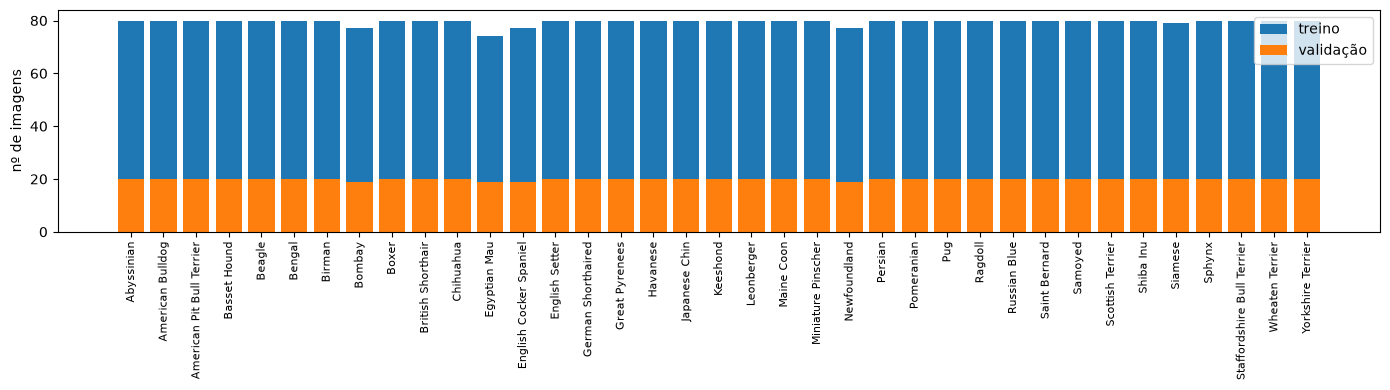

In [3]:
labels = train.dataset._labels
count_train = Counter(labels[i] for i in train.indices)
count_val = Counter(labels[i] for i in val.indices)

idx = range(len(classes))
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(idx, [count_train[i] for i in idx], label="treino")
ax.bar(idx, [count_val[i] for i in idx], label="validação")
ax.set_xticks(list(idx), classes, rotation=90, fontsize=8)
ax.set_ylabel("nº de imagens")
ax.legend()
plt.tight_layout()

### 1.2 O que as transforms fazem com uma imagem

- **Original**: a foto como está no disco (tamanhos variados).
- **Treino**: cada vez que a imagem é carregada, sai um recorte e espelhamento diferentes (aumento de dados).
- **Avaliação**: sempre o mesmo resultado, com o centro da imagem em 224×224 e sem distorcer a proporção.

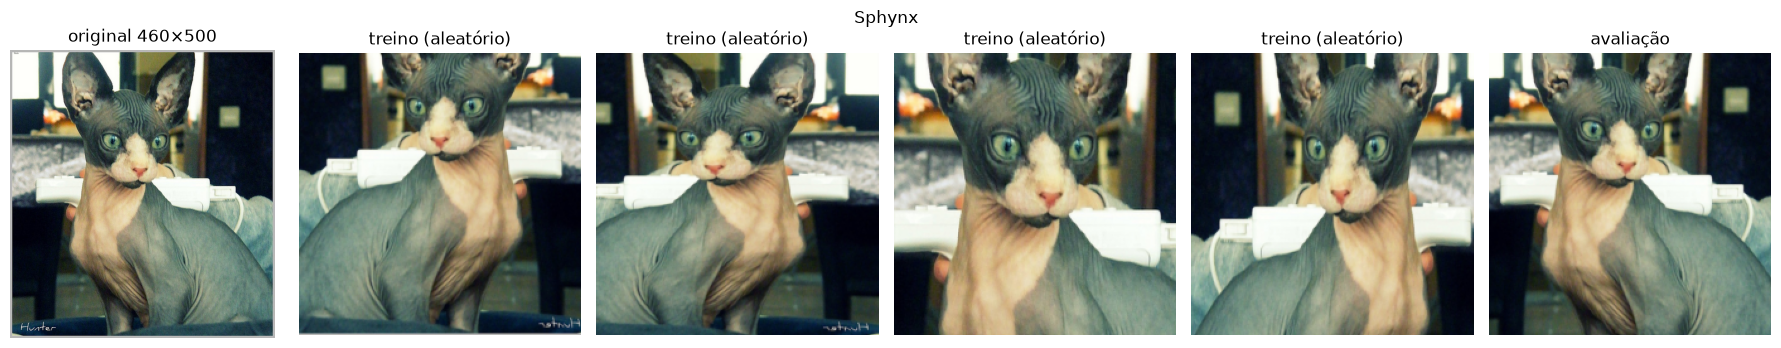

In [4]:
path = train.dataset._images[train.indices[0]]
img = Image.open(path).convert("RGB")
t_train, t_eval = get_transforms(train=True), get_transforms(train=False)

fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
axes[0].imshow(img)
axes[0].set_title(f"original {img.size[0]}×{img.size[1]}")
for ax in axes[1:5]:
    ax.imshow(denormalize(t_train(img)))
    ax.set_title("treino (aleatório)")
axes[5].imshow(denormalize(t_eval(img)))
axes[5].set_title("avaliação")
for ax in axes:
    ax.axis("off")
plt.suptitle(classes[labels[train.indices[0]]])
plt.tight_layout()

### 1.3 Um batch

O modelo recebe tensores no formato `(batch, canais, altura, largura)`. Depois da normalização, os valores ficam em torno de média 0 e desvio 1 (não mais entre 0 e 255).

imagens: (16, 3, 224, 224) torch.float32
rótulos: (16,) [6, 8, 12, 0, 7, 23, 4, 12]
média: -0.316 | desvio: 1.076


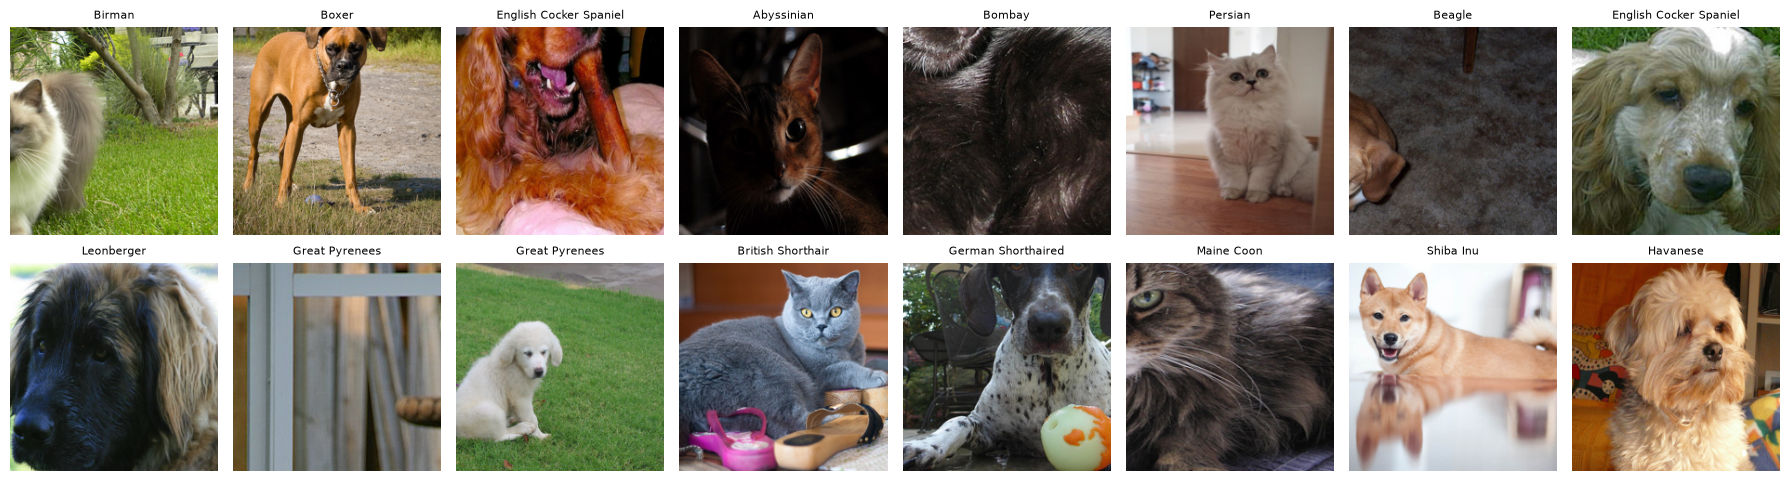

In [5]:
train_loader, val_loader, test_loader = make_loaders(train, val, test)
x, y = next(iter(train_loader))
print("imagens:", tuple(x.shape), x.dtype)
print("rótulos:", tuple(y.shape), y[:8].tolist())
print(f"média: {x.mean():.3f} | desvio: {x.std():.3f}")

fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for ax, xi, yi in zip(axes.flat, x, y):
    ax.imshow(denormalize(xi))
    ax.set_title(classes[yi], fontsize=8)
    ax.axis("off")
plt.tight_layout()

## 2. Modelos e regimes

Cada modelo é um backbone pré-treinado com a última camada trocada por uma nova (37 saídas). O regime decide o que treina:

- **linear**: só a cabeça nova
- **partial**: a cabeça + o último quarto dos blocos (ResNet18: `layer4` · MobileNetV2: `features[14:]` · ViT: últimos 3 de 12 blocos)
- **full**: tudo

In [6]:
import pandas as pd
import torch
from models import BACKBONES, REGIMES, build_model, count_params

rows = []
for b in BACKBONES:
    for r in REGIMES:
        total, trainable = count_params(build_model(b, num_classes=len(classes), regime=r))
        rows.append({"modelo": b, "regime": r, "total (M)": total / 1e6,
                     "treináveis (M)": trainable / 1e6, "% treinável": 100 * trainable / total})
pd.DataFrame(rows).round(2)

/Users/eduardaveras/Documents/Mestrado/gatinhas-dl/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,modelo,regime,total (M),treináveis (M),% treinável
0,resnet18,linear,11.20,0.02,0.17
1,resnet18,partial,11.20,8.41,75.14
2,resnet18,full,11.20,11.20,100.00
3,mobilenet_v2,linear,2.27,0.05,2.09
4,mobilenet_v2,partial,2.27,1.73,76.11
5,mobilenet_v2,full,2.27,2.27,100.00
6,dinov2_vits14,linear,21.64,0.01,0.07
7,dinov2_vits14,partial,21.64,5.34,24.68
8,dinov2_vits14,full,21.64,21.64,100.00


## 3. Resultados

O treino roda **fora** do notebook (~4 h, incluindo o teste de LR). No terminal, da raiz do projeto, com os outros apps fechados:

```bash
caffeinate -i venv/bin/python src/run_baseline.py
```

Esta seção só lê o que foi salvo em `results/`. As figuras também são salvas em `results/figures/` para o relatório.

In [7]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(exist_ok=True)

# Figuras no tamanho de uma coluna do IEEE (3,5"), com fonte do tamanho do texto do artigo
plt.rcParams.update({"font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
                     "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7})
COLUMN_WIDTH = 3.5
TITLES = {"resnet18": "ResNet18", "mobilenet_v2": "MobileNetV2", "dinov2_vits14": "ViT-S/14 DINOv2"}
REGIME_NAMES = {"linear": "Linear", "partial": "Parcial", "full": "Completo"}
COLORS = {"linear": "#2a78d6", "partial": "#eb6834", "full": "#1baf7a"}

all_runs = pd.read_csv(RESULTS / "summary.csv")
summary = all_runs[(all_runs["dataset"] == "pets") & (all_runs["experiment"] == "baseline")]
summary[["backbone", "regime", "best_epoch", "best_val_acc", "test_acc", "test_f1",
         "params_trainable", "train_time_s"]].round(3)

,backbone,regime,best_epoch,best_val_acc,test_acc,test_f1,params_trainable,train_time_s
0,resnet18,linear,11,0.924,0.890,0.889,18981,553.315
1,resnet18,partial,13,0.921,0.898,0.896,8412709,791.241
2,resnet18,full,15,0.925,0.897,0.895,11195493,1221.341
3,mobilenet_v2,linear,12,0.925,0.905,0.904,47397,370.606
4,mobilenet_v2,partial,15,0.932,0.908,0.907,1728741,471.899
5,mobilenet_v2,full,12,0.940,0.903,0.901,2271269,930.561
6,dinov2_vits14,linear,10,0.957,0.947,0.946,14245,1357.391
7,dinov2_vits14,partial,14,0.963,0.952,0.951,5340709,1817.726
8,dinov2_vits14,full,14,0.958,0.945,0.945,21643045,3410.511


### 3.1 Tabela 3 × 3: acurácia no teste (%)

In [8]:
table = (summary.pivot(index="backbone", columns="regime", values="test_acc")
         .reindex(index=list(BACKBONES), columns=list(REGIMES)))
(100 * table).round(1)

regime,linear,partial,full
backbone,,,
resnet18,89.0,89.8,89.7
mobilenet_v2,90.5,90.8,90.3
dinov2_vits14,94.7,95.2,94.5


### 3.2 Curvas de treino

Linha cheia: validação. Tracejada: treino. Quanto mais as duas se afastam, mais overfitting.

A acurácia de treino é medida nas imagens **com** aumento de dados e ao longo da época, enquanto o modelo ainda muda. Por isso ela pode ficar abaixo da validação no início.

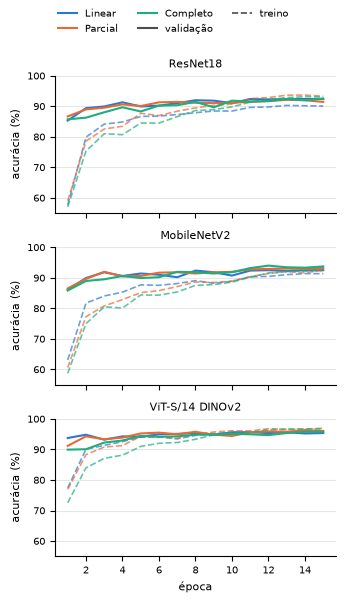

In [9]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(3, 1, figsize=(COLUMN_WIDTH, 6), sharex=True, sharey=True)
for ax, b in zip(axes, BACKBONES):
    for r in REGIMES:
        path = RESULTS / "csv" / f"pets_{b}_{r}_s42.csv"
        if not path.exists():
            continue
        h = pd.read_csv(path)
        ax.plot(h["epoch"], 100 * h["val_acc"], color=COLORS[r], lw=1.5)
        ax.plot(h["epoch"], 100 * h["train_acc"], color=COLORS[r], lw=1.2, ls="--", alpha=0.7)
    ax.set_title(TITLES[b])
    ax.set_ylabel("acurácia (%)")
    ax.set_ylim(55, 100)
    ax.grid(axis="y", color="0.9")
    ax.spines[["top", "right"]].set_visible(False)
axes[-1].set_xlabel("época")

handles = [Line2D([], [], color=COLORS[r], lw=1.5, label=REGIME_NAMES[r]) for r in REGIMES]
handles += [Line2D([], [], color="0.3", lw=1.5, label="validação"),
            Line2D([], [], color="0.3", lw=1.2, ls="--", label="treino")]
fig.legend(handles=handles, loc="upper center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig(FIGURES / "pets_curvas.png", dpi=300)

### 3.3 Onde o melhor modelo erra

Matriz de confusão no teste (normalizada por linha: cada linha soma 1) e os pares de raças mais confundidos.

Pares mais confundidos (verdadeiro → predito):
  Staffordshire Bull Terrier   → American Pit Bull Terrier    17
  American Pit Bull Terrier    → Staffordshire Bull Terrier   14
  American Pit Bull Terrier    → American Bulldog             11
  Birman                       → Ragdoll                      11
  Egyptian Mau                 → Bengal                       11
  Ragdoll                      → Birman                       10
  Boxer                        → American Bulldog             6
  Staffordshire Bull Terrier   → American Bulldog             6
  British Shorthair            → Russian Blue                 5
  Siamese                      → Birman                       5


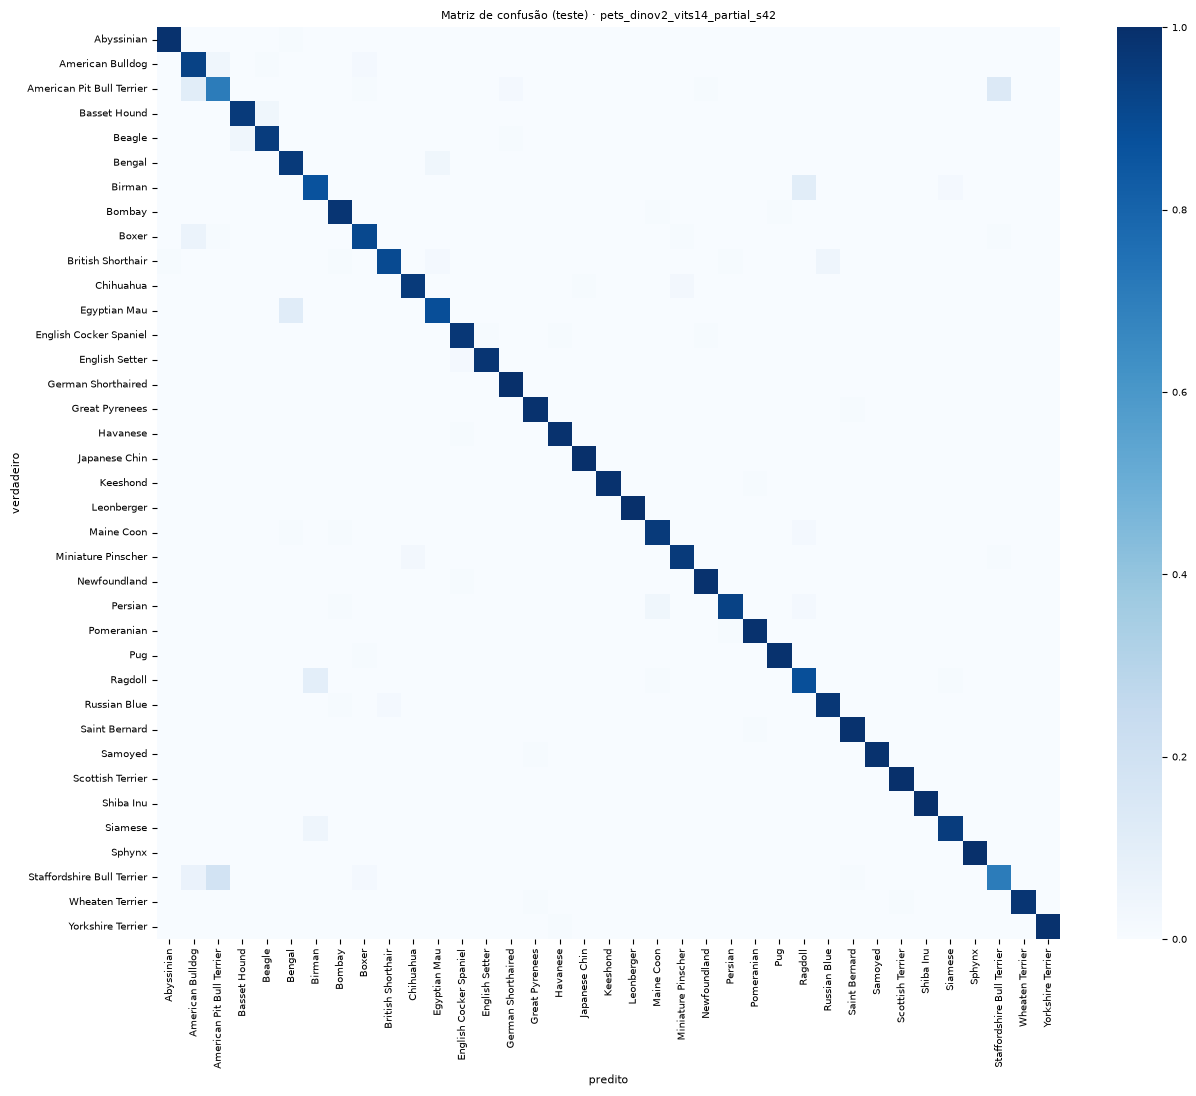

In [10]:
best = summary.loc[summary["test_acc"].idxmax(), "run"]
p = pd.read_csv(RESULTS / "preds" / f"{best}.csv")

cm = confusion_matrix(p["label"], p["pred"], normalize="true")
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(cm, cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax)
ax.set_title(f"Matriz de confusão (teste) · {best}")
ax.set_xlabel("predito")
ax.set_ylabel("verdadeiro")
plt.tight_layout()
plt.savefig(FIGURES / "pets_confusao.png", dpi=150)

print("Pares mais confundidos (verdadeiro → predito):")
for (true, pred), n in p[p["label"] != p["pred"]].value_counts(["label", "pred"]).head(10).items():
    print(f"  {classes[true]:28s} → {classes[pred]:28s} {n}")

### 3.4 Efeito da taxa de aprendizado no full fine-tuning

O mesmo experimento do baseline, mudando **só** a LR do backbone para 10× a receita padrão (CNNs: `1e-4` → `1e-3`; DINOv2: `1e-5` → `1e-4`). Se a LR alta destrói as features pré-treinadas, a validação deve ficar bem abaixo.

,backbone,experiment,backbone_lr,best_val_acc,test_acc
2,resnet18,baseline,0.00010,0.925,0.897
5,mobilenet_v2,baseline,0.00010,0.940,0.903
8,dinov2_vits14,baseline,0.00001,0.958,0.945
9,resnet18,lr_alta,0.00100,0.856,0.815
10,dinov2_vits14,lr_alta,0.00010,0.215,0.173
11,mobilenet_v2,lr_alta,0.00100,0.894,0.851


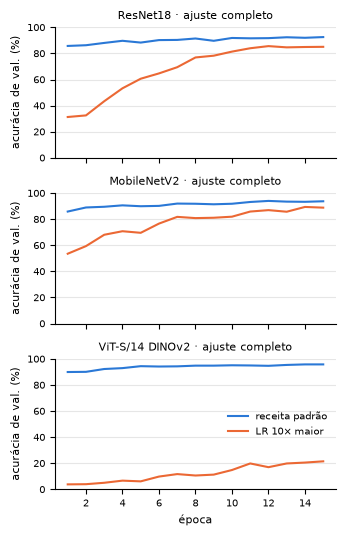

In [11]:
# LR das camadas pré-treinadas: baseline e 10x maior
LRS = {"resnet18": ("10^{-4}", "10^{-3}"), "mobilenet_v2": ("10^{-4}", "10^{-3}"),
       "dinov2_vits14": ("10^{-5}", "10^{-4}")}

fig, axes = plt.subplots(3, 1, figsize=(COLUMN_WIDTH, 5.4), sharex=True, sharey=True)
for ax, b in zip(axes, BACKBONES):
    base, alta = LRS[b]
    for exp, label, color in [("", f"LR ${base}$ (baseline)", "#2a78d6"), ("_lr_alta", f"LR ${alta}$", "#eb6834")]:
        path = RESULTS / "csv" / f"pets_{b}_full_s42{exp}.csv"
        if path.exists():
            h = pd.read_csv(path)
            ax.plot(h["epoch"], 100 * h["val_acc"], color=color, lw=1.5, label=label)
    ax.set_title(f"{TITLES[b]} · ajuste completo")
    ax.set_ylabel("acurácia de val. (%)")
    ax.set_ylim(0, 100)
    ax.grid(axis="y", color="0.9")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="center right", frameon=False)
axes[-1].set_xlabel("época")
plt.tight_layout()
plt.savefig(FIGURES / "pets_lr.png", dpi=300)

all_runs[all_runs["regime"] == "full"][["backbone", "experiment", "backbone_lr", "best_val_acc", "test_acc"]].round({"best_val_acc": 3, "test_acc": 3})

### 3.5 Gatos × cães

Acurácia no teste separada por espécie (12 raças de gatos, 25 de cães). O ImageNet tem muitas raças de cães e poucas classes de gatos: as features de cachorro já vêm prontas, as de gato precisam de mais ajuste.

,backbone,regime,gatos,cães
0,resnet18,linear,82.1,92.4
1,resnet18,partial,86.8,91.2
2,resnet18,full,88.0,90.5
3,mobilenet_v2,linear,85.0,93.2
4,mobilenet_v2,partial,87.8,92.2
5,mobilenet_v2,full,87.4,91.6
6,dinov2_vits14,linear,93.0,95.5
7,dinov2_vits14,partial,93.9,95.8
8,dinov2_vits14,full,92.6,95.5


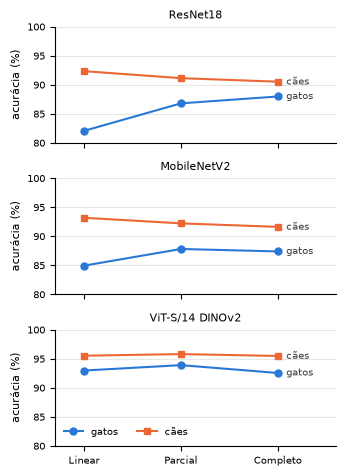

In [12]:
CAT_BREEDS = {"Abyssinian", "Bengal", "Birman", "Bombay", "British Shorthair", "Egyptian Mau",
              "Maine Coon", "Persian", "Ragdoll", "Russian Blue", "Siamese", "Sphynx"}
cat_ids = [i for i, c in enumerate(classes) if c in CAT_BREEDS]

rows = []
for _, run in summary.iterrows():
    p = pd.read_csv(RESULTS / "preds" / f"{run['run']}.csv")
    correct = p["label"] == p["pred"]
    is_cat = p["label"].isin(cat_ids)
    rows.append({"backbone": run["backbone"], "regime": run["regime"],
                 "gatos": correct[is_cat].mean(), "cães": correct[~is_cat].mean()})
species = pd.DataFrame(rows)

STYLE = {"gatos": dict(color="#2a78d6", marker="o"), "cães": dict(color="#eb6834", marker="s")}
fig, axes = plt.subplots(3, 1, figsize=(COLUMN_WIDTH, 4.8), sharex=True, sharey=True)
for ax, b in zip(axes, BACKBONES):
    d = species[species["backbone"] == b].set_index("regime").loc[list(REGIMES)]
    for sp, style in STYLE.items():
        ax.plot(range(3), 100 * d[sp], lw=1.5, ms=5, label=sp, **style)
        ax.annotate(sp, (2, 100 * d[sp].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=7, color="0.25")
    ax.set_title(TITLES[b])
    ax.set_ylabel("acurácia (%)")
    ax.set_xlim(-0.3, 2.6)
    ax.set_ylim(80, 100)
    ax.set_yticks(range(80, 101, 5))
    ax.grid(axis="y", color="0.9")
    ax.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(range(3), [REGIME_NAMES[r] for r in REGIMES])
axes[-1].legend(loc="lower left", frameon=False, ncol=2)
plt.tight_layout()
plt.savefig(FIGURES / "pets_gatos_caes.png", dpi=300)

species.assign(gatos=lambda d: (100 * d["gatos"]).round(1), cães=lambda d: (100 * d["cães"]).round(1))